In [10]:
# Step 1: Understand your project directory
# Apply statistical methods and time-series analysis to investigate electricity consumption patterns, 
# identify seasonal behaviour within the available period and examine relationships between 
# environmental conditions and electricity demand

In [11]:
# Step 2: Import the required libraries
!mamba install pandas numpy matplotlib seaborn scipy statsmodels plotly 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
import plotly.express as px
import plotly.graph_objects as go

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, statsmodels, plotly
Channels: emscripten-forge-4x, conda-forge

Solving environment...
error sending request
Solving environment...
Solving took 7.107 seconds
All requested packages already installed.


In [12]:
# Step 3: Load the datasets
# Loading the main electricity consumption dataset
df = pd.read_csv("powerconsumption.csv")

# Loading the data dictionary
data_dictionary = pd.read_csv("powerconsumption_datadictionary.csv")

In [13]:
# Step 4: inspection:

print("Main Dataset:")
display(df.head())

print("Data Dictionary:")
display(data_dictionary)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Main Dataset:


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


Data Dictionary:


,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


Dataset Shape: (52416, 9)

Column Names:
['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

Data Types:
Datetime                      str
Temperature               float64
Humidity                  float64
WindSpeed                 float64
GeneralDiffuseFlows       float64
DiffuseFlows              float64
PowerConsumption_Zone1    float64
PowerConsumption_Zone2    float64
PowerConsumption_Zone3    float64
dtype: object


In [14]:
# Task 1: Data Import and Initial Exploration

# 2. LOAD THE DATASETS

# Load the main electricity consumption dataset
df = pd.read_csv("powerconsumption.csv")

# Load the accompanying data dictionary
data_dictionary = pd.read_csv("powerconsumption_datadictionary.csv")


# 3. EXAMINE THE MAIN DATASET

# Display the first five observations
print("FIRST FIVE OBSERVATIONS")
display(df.head())

# Display the last five observations
print("\nLAST FIVE OBSERVATIONS")
display(df.tail())


# 4. EXAMINE DATASET DIMENSIONS

# Determine the number of rows and columns
print("\nDATASET DIMENSIONS")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)


# 5. EXAMINE DATASET STRUCTURE AND VARIABLE TYPES

# Display column information, data types and non-null counts
print("\nDATASET INFORMATION")
df.info()

# Display the data type of each column
print("\nCOLUMN DATA TYPES")
print(df.dtypes)

# Display all column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())


# 6. EXAMINE THE DATA DICTIONARY

# Display the descriptions of the dataset variables
print("\nDATA DICTIONARY")
display(data_dictionary)

# Examine the structure of the data dictionary
print("\nDATA DICTIONARY DIMENSIONS")
print(data_dictionary.shape)

print("\nDATA DICTIONARY INFORMATION")
data_dictionary.info()

FIRST FIVE OBSERVATIONS


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964



LAST FIVE OBSERVATIONS


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
52411,12/30/2017 23:10,7.010,72.4,0.080,0.040,0.096,31160.45627,26857.31820,14780.31212
52412,12/30/2017 23:20,6.947,72.6,0.082,0.051,0.093,30430.41825,26124.57809,14428.81152
52413,12/30/2017 23:30,6.900,72.8,0.086,0.084,0.074,29590.87452,25277.69254,13806.48259
52414,12/30/2017 23:40,6.758,73.0,0.080,0.066,0.089,28958.17490,24692.23688,13512.60504
52415,12/30/2017 23:50,6.580,74.1,0.081,0.062,0.111,28349.80989,24055.23167,13345.49820



DATASET DIMENSIONS
Number of Rows: 52416
Number of Columns: 9
Dataset Shape: (52416, 9)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.4 MB

COLUMN DATA TYPES
Datetime                      str
Temperature               float64
Humidity                  float64
WindSpeed                 float64
General

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...



DATA DICTIONARY DIMENSIONS
(9, 2)

DATA DICTIONARY INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Field        9 non-null      str  
 1   Description  9 non-null      str  
dtypes: str(2)
memory usage: 144.0 bytes


<!-- Our initial inspection confirms:
1. The dataset has the expected 52,416 observations.
2. All nine expected columns are present.
3. All columns have 52,416 non-null values.
4. Eight columns are numerical.
5. Datetime requires conversion.
6. The supplied dictionary does not establish measurement units.
One clarification: df.info() reports non-null counts, but it does not identify every possible data quality issue. We'll still check duplicates and other inconsistencies. -->

<!-- Our initial inspection confirms:
1. The dataset has the expected 52,416 observations.
2. All nine expected columns are present.
3. All columns have 52,416 non-null values.
4. Eight columns are numerical.
5. Datetime requires conversion.
6. The supplied dictionary does not establish measurement units.
One clarification: df.info() reports non-null counts, but it does not identify every possible data quality issue. We'll still check duplicates and other inconsistencies. -->

<!-- Our initial inspection confirms:
1. The dataset has the expected 52,416 observations.
2. All nine expected columns are present.
3. All columns have 52,416 non-null values.
4. Eight columns are numerical.
5. Datetime requires conversion.
6. The supplied dictionary does not establish measurement units.
One clarification: df.info() reports non-null counts, but it does not identify every possible data quality issue. We'll still check duplicates and other inconsistencies. -->

In [15]:
# Missing values, duplicates and datetime validation

# 1. CHECK FOR MISSING VALUES

print("MISSING VALUES PER COLUMN")
print(df.isnull().sum())

# Calculate the percentage of missing values in each column
print("\nMISSING VALUES PERCENTAGE")
print((df.isnull().mean() * 100).round(2))


# 2. CHECK FOR DUPLICATE OBSERVATIONS

# Count complete duplicate rows
duplicate_rows = df.duplicated().sum()

print("\nDUPLICATE OBSERVATIONS")
print("Total Duplicate Rows:", duplicate_rows)


# 3. CONVERT DATETIME TO A PROPER DATETIME FORMAT

# Convert the Datetime column from string to datetime
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

# Verify the conversion
print("\nDATETIME DATA TYPE")
print(df["Datetime"].dtype)

# Check for invalid datetime values after conversion
print("Invalid Datetime Values:", df["Datetime"].isna().sum())


# 4. EXAMINE THE DATE RANGE

print("\nDATASET DATE RANGE")
print("First Observation:", df["Datetime"].min())
print("Last Observation:", df["Datetime"].max())


# 5. CHECK CHRONOLOGICAL ORDER

print("\nCHRONOLOGICAL ORDER")
print("Is Dataset Chronologically Sorted:",
      df["Datetime"].is_monotonic_increasing)


# 6. CHECK FOR DUPLICATE TIMESTAMPS

print("\nDUPLICATE TIMESTAMPS")
print("Total Duplicate Timestamps:",
      df["Datetime"].duplicated().sum())


# 7. CHECK THE CONSISTENCY OF 10-MINUTE INTERVALS

# Calculate the difference between consecutive timestamps
time_intervals = df["Datetime"].diff()

# Count the frequency of each time interval
print("\nTIME INTERVAL DISTRIBUTION")
print(time_intervals.value_counts().head(10))

# Identify intervals that differ from the expected 10 minutes
expected_interval = pd.Timedelta(minutes=10)

inconsistent_intervals = time_intervals[
    time_intervals.notna() &
    (time_intervals != expected_interval)
]

print("\nRECORDING INTERVAL CONSISTENCY")
print("Expected Interval:", expected_interval)
print("Inconsistent Intervals:", len(inconsistent_intervals))

MISSING VALUES PER COLUMN
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

MISSING VALUES PERCENTAGE
Datetime                  0.0
Temperature               0.0
Humidity                  0.0
WindSpeed                 0.0
GeneralDiffuseFlows       0.0
DiffuseFlows              0.0
PowerConsumption_Zone1    0.0
PowerConsumption_Zone2    0.0
PowerConsumption_Zone3    0.0
dtype: float64

DUPLICATE OBSERVATIONS
Total Duplicate Rows: 0

DATETIME DATA TYPE
datetime64[us]
Invalid Datetime Values: 0

DATASET DATE RANGE
First Observation: 2017-01-01 00:00:00
Last Observation: 2017-12-30 23:50:00

CHRONOLOGICAL ORDER
Is Dataset Chronologically Sorted: True

DUPLICATE TIMESTAMPS
Total Duplicate Timestamps: 0

TIME INTERVAL DISTRIBUTION
Datetime
0 days 00:10:00    52415
Name: count, dt

In [16]:
# Summarize key characteristics

# 1. GENERATE DESCRIPTIVE STATISTICS FOR NUMERICAL VARIABLES

print("NUMERICAL VARIABLE SUMMARY")

display(df.describe())


# 2. IDENTIFY THE DATASET'S NUMERICAL AND NON-NUMERICAL COLUMNS

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

non_numerical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNUMERICAL COLUMNS:")
print(numerical_columns)

print("\nNON-NUMERICAL COLUMNS:")
print(non_numerical_columns)


# 3. CHECK THE NUMBER OF UNIQUE VALUES IN EACH COLUMN

print("\nUNIQUE VALUES PER COLUMN")
print(df.nunique())


# 4. VERIFY THE DATASET'S FINAL STRUCTURE

print("\nFINAL DATASET STRUCTURE")
print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Datetime Data Type:", df["Datetime"].dtype)

NUMERICAL VARIABLE SUMMARY


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,2017-07-01 23:55:00,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
min,2017-01-01 00:00:00,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,2017-04-01 23:57:30,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,2017-07-01 23:55:00,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,2017-09-30 23:52:30,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,2017-12-30 23:50:00,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099



NUMERICAL COLUMNS:
['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

NON-NUMERICAL COLUMNS:
['Datetime']

UNIQUE VALUES PER COLUMN
Datetime                  52416
Temperature                3437
Humidity                   4443
WindSpeed                   548
GeneralDiffuseFlows       10504
DiffuseFlows              10449
PowerConsumption_Zone1    27709
PowerConsumption_Zone2    29621
PowerConsumption_Zone3    22838
dtype: int64

FINAL DATASET STRUCTURE
Shape: (52416, 9)
Missing Values: 0
Duplicate Rows: 0
Datetime Data Type: datetime64[us]


In [17]:
# Generate descriptive statistics for numerical variables only
numerical_summary = df.select_dtypes(include=np.number).describe()

display(numerical_summary)

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


<!-- The question was:

If Zone 1 has an average consumption of 32,344.97 and Zone 2 has an average consumption of 21,042.51, can we conclude that Zone 1 is less energy-efficient?

Answer: No.

Here's why.

Electricity consumption measures how much electricity a zone uses, not how efficiently it uses electricity.

To assess energy efficiency, we would need additional information, such as:
- Number of households or customers in each zone.
- Population of each geographical zone.
- Industrial and commercial activities.
- Electricity consumption relative to economic or productive output.
For example, a zone with more industries might naturally consume more electricity while still being more energy-efficient per unit of production.

This is an important distinction between consumption analysis and energy efficiency analysis. -->

<!-- Task 2 : Statistical Summary
Our objective is to use Pandas, NumPy and SciPy to understand the statistical characteristics of electricity consumption across the three geographical zones. -->

In [18]:
# TASK 2: STATISTICAL SUMMARY
# 1. SELECT THE THREE ELECTRICITY CONSUMPTION VARIABLES

consumption_columns = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]

# Create a separate DataFrame containing consumption data
consumption_df = df[consumption_columns]


# 2. CALCULATE CENTRAL TENDENCY

# Mean: Average consumption
mean_values = consumption_df.mean()

# Median: Middle consumption value
median_values = consumption_df.median()


# 3. CALCULATE DISPERSION

# Minimum and maximum consumption
min_values = consumption_df.min()
max_values = consumption_df.max()

# Standard deviation: Spread around the mean
std_values = consumption_df.std()

# Variance: Squared dispersion around the mean
variance_values = consumption_df.var()


# 4. CALCULATE QUARTILES AND INTERQUARTILE RANGE

# First quartile (25th percentile)
q1_values = consumption_df.quantile(0.25)

# Second quartile (50th percentile)
q2_values = consumption_df.quantile(0.50)

# Third quartile (75th percentile)
q3_values = consumption_df.quantile(0.75)

# Interquartile range
iqr_values = q3_values - q1_values


# 5. CALCULATE DISTRIBUTION SUMMARIES

# Skewness: Measures distribution asymmetry
skewness_values = consumption_df.skew()

# Kurtosis: Measures excess kurtosis
kurtosis_values = consumption_df.kurtosis()


# 6. CALCULATE RELATIVE VARIABILITY

# Coefficient of Variation (CV)
# Expressed as a percentage of the mean
cv_values = (std_values / mean_values) * 100


# 7. COMBINE ALL STATISTICS INTO ONE TABLE

statistical_summary = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Minimum": min_values,
    "Maximum": max_values,
    "Standard Deviation": std_values,
    "Variance": variance_values,
    "Q1": q1_values,
    "Q2": q2_values,
    "Q3": q3_values,
    "IQR": iqr_values,
    "Skewness": skewness_values,
    "Kurtosis": kurtosis_values,
    "CV (%)": cv_values
})

# Display the complete statistical summary
display(statistical_summary.round(3))

,Mean,Median,Minimum,Maximum,Standard Deviation,Variance,Q1,Q2,Q3,IQR,Skewness,Kurtosis,CV (%)
PowerConsumption_Zone1,32344.971,32265.920,13895.696,52204.395,7130.563,5.084492e+07,26310.669,32265.920,37309.018,10998.349,0.229,-0.754,22.045
PowerConsumption_Zone2,21042.509,20823.168,8560.081,37408.861,5201.466,2.705525e+07,16980.766,20823.168,24713.718,7732.951,0.329,-0.437,24.719
PowerConsumption_Zone3,17835.406,16415.117,5935.174,47598.326,6622.165,4.385307e+07,13129.327,16415.117,21624.100,8494.774,1.024,1.086,37.129


<!-- standard deviation measures absolute spread, while CV measures spread relative to the mean.
Task 2: Main findings
Your descriptive analysis supports these findings:
1. Zone 1 records the highest average electricity consumption.
2. Zone 3 has the highest relative variability.
3. Zone 1 has the highest absolute standard deviation.
4. Zone 3 shows the strongest positive skewness and positive excess kurtosis.
5. The three zones have different consumption levels and distribution characteristics.
One important caution: these findings describe consumption patterns. They do not establish which zone is more energy-efficient. -->

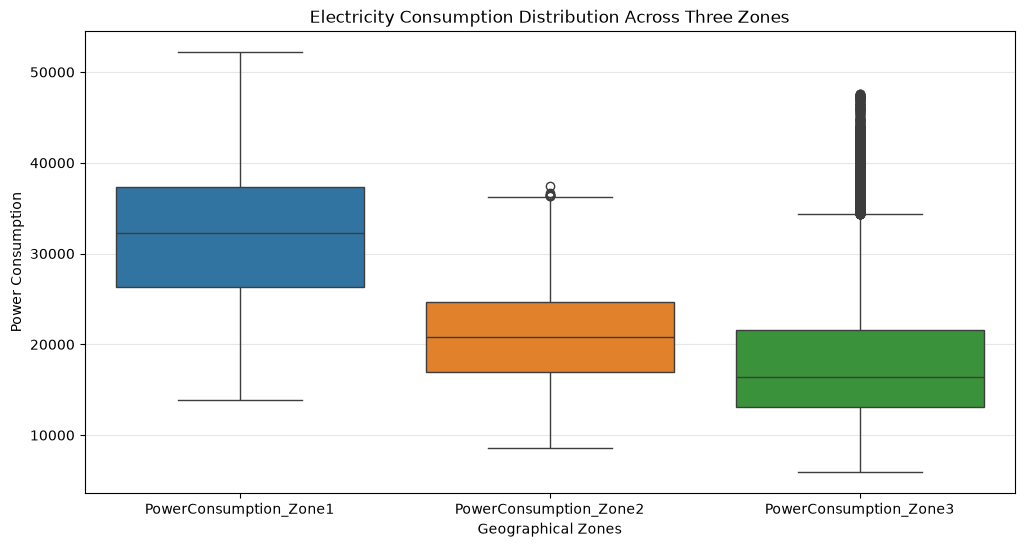

In [20]:
# Visualising the consumption distributions
# Compare the consumption distributions across the three zones

import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=consumption_df)

plt.title("Electricity Consumption Distribution Across Three Zones")
plt.xlabel("Geographical Zones")
plt.ylabel("Power Consumption")
plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)
plt.show()

<!-- Final interpretation for Task 2
The boxplot comparison indicates that Zone 1 has the highest typical electricity consumption, followed by Zone 2 and Zone 3. Zone 1 also exhibits considerable variation in consumption. Zone 2 has a relatively narrower distribution, although some high-consumption outliers are present. Zone 3 displays several extreme upper outliers and a positively skewed distribution, suggesting occasional periods of unusually high consumption despite having the lowest average consumption. These findings indicate differences in both consumption levels and variability across the three geographical zones. -->

<!-- Task 3: Time-Series Analysis
Now we move from understanding the distribution of consumption to understanding how electricity consumption changes over time. -->
<!-- We will use hourly observations as our primary time-series frequency. This gives us enough detail to examine daily and weekly consumption cycles while reducing the noise in the original 10-minute readings. We can then aggregate hourly observations into daily and monthly summaries.

One important methodological point: we will use hourly averages because the dataset's measurement units and precise meaning are not documented. We should not assume that summing the readings gives total energy consumption. -->

In [21]:
# Step 1: Aggregate readings into hourly observations

# TASK 3: TIME-SERIES ANALYSIS

# Set Datetime as the index
df_time = df.set_index("Datetime").copy()

# Select electricity consumption columns
consumption_columns = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]

# Aggregate 10-minute readings into hourly averages
hourly_consumption = (
    df_time[consumption_columns]
    .resample("h")
    .mean()
)

# Display the first five observations
print("HOURLY ELECTRICITY CONSUMPTION")
display(hourly_consumption.head())

# Check dataset dimensions
print("Dataset shape:", hourly_consumption.shape)

# Check for missing values
print("\nMissing values:")
print(hourly_consumption.isnull().sum())

# Why hourly averages?

# Hourly aggregation reduces the number of observations and makes recurring patterns easier to identify. 
# It also retains the hourly variation needed to investigate daily and weekly cycles.

HOURLY ELECTRICITY CONSUMPTION


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Datetime,,,
2017-01-01 00:00:00,29197.974683,18026.747720,19252.048193
2017-01-01 01:00:00,24657.215190,16078.419453,17042.891567
2017-01-01 02:00:00,22083.037973,14330.699088,15676.144578
2017-01-01 03:00:00,20811.139240,13219.452887,14883.855422
2017-01-01 04:00:00,20475.949367,12921.580547,14317.108433


Dataset shape: (8736, 3)

Missing values:
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64


AVERAGE ELECTRICITY CONSUMPTION BY HOUR


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


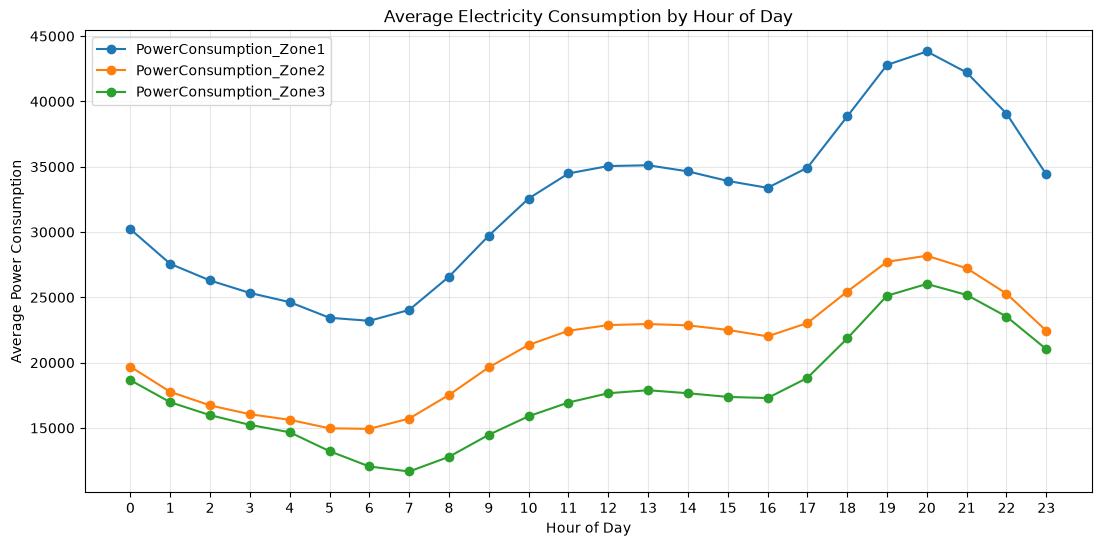

In [22]:
# Step 2: Examine hourly consumption patterns

# Extract the hour from the datetime index
hourly_consumption["Hour"] = hourly_consumption.index.hour

# Calculate average consumption for each hour
hourly_pattern = (
    hourly_consumption
    .groupby("Hour")[consumption_columns]
    .mean()
)

# Display hourly averages
print("AVERAGE ELECTRICITY CONSUMPTION BY HOUR")
display(hourly_pattern.round(2))

# Visualize hourly consumption patterns
plt.figure(figsize=(13, 6))

for column in consumption_columns:
    plt.plot(
        hourly_pattern.index,
        hourly_pattern[column],
        marker="o",
        label=column
    )

plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power Consumption")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


<!-- 1. Early morning decline

Consumption generally decreases from midnight towards the early morning hours. The lowest average readings occur around 6–7 AM, depending on the zone.

2. Daytime increase

Consumption begins increasing after the early morning hours. All three zones experience higher consumption around midday.

3. Evening peak

The strongest increase occurs between approximately 5 PM and 8 PM. At 8 PM, all three zones reach their highest average hourly consumption.

4. Similar patterns across zones

Although the consumption levels differ, the three zones follow broadly similar hourly patterns. This suggests that they may share some common daily demand cycles.
Report-ready interpretation
The hourly analysis reveals a recurring daily consumption pattern across the three geographical zones. Electricity consumption generally declines during the early morning hours, begins increasing throughout the morning, and remains relatively high during the afternoon. A pronounced increase occurs during the evening, with all three zones recording their highest average consumption at approximately 8 PM. Zone 1 consistently records the highest consumption, followed by Zone 2 and Zone 3. These patterns suggest that electricity demand varies considerably throughout the day, with evening hours representing the peak consumption period. -->

DAILY AVERAGE ELECTRICITY CONSUMPTION


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Datetime,,,
2017-01-01,28465.232067,17737.791287,17868.795181
2017-01-02,28869.493671,19557.725431,17820.763053
2017-01-03,30562.447257,20057.269504,17620.803213
2017-01-04,30689.831224,20102.077001,17673.694779
2017-01-05,30802.911393,20033.941237,17664.176707


Daily dataset shape: (364, 3)

Daily consumption summary:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,364.00,364.00,364.00
mean,32344.97,21042.51,17835.41
std,2669.37,2708.56,4904.52
min,26771.52,14779.10,10530.61
25%,30531.19,19046.52,14265.35
50%,31920.99,20807.35,17421.57
75%,34100.78,23344.34,18933.35
max,38733.50,28354.54,32700.21


AVERAGE ELECTRICITY CONSUMPTION BY DAY


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


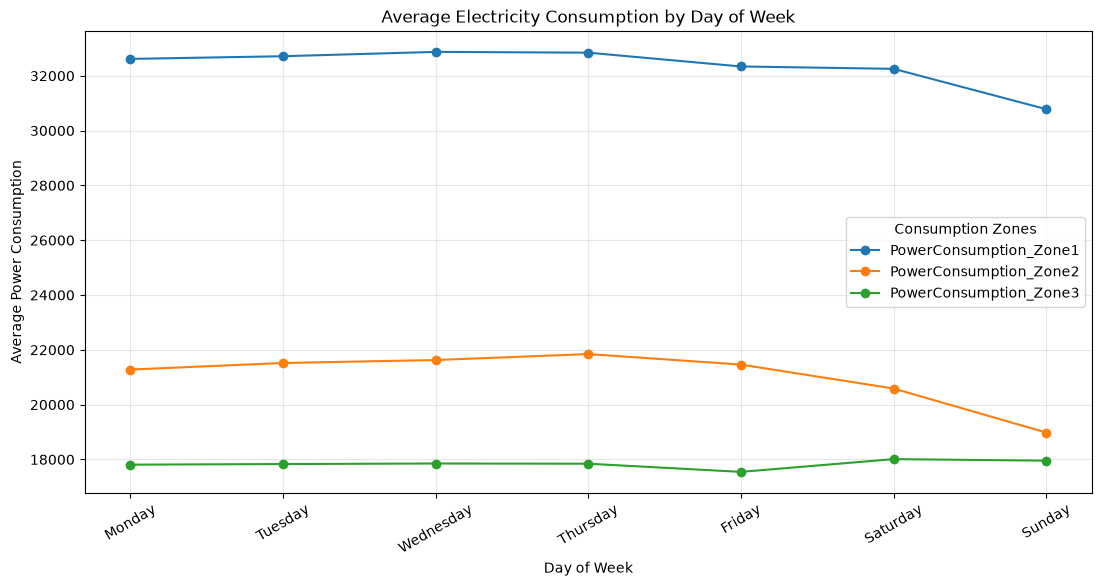

In [23]:
# Daily and weekly consumption patterns
# We now want to investigate whether consumption changes depending on the day of the week.
# Calculate daily average consumption

# Aggregate the original data into daily averages
daily_consumption = (
    df_time[consumption_columns]
    .resample("D")
    .mean()
)

# Display the first five days
print("DAILY AVERAGE ELECTRICITY CONSUMPTION")
display(daily_consumption.head())

# Examine the daily dataset
print("Daily dataset shape:", daily_consumption.shape)

# CalcExamine weekly patternsulate descriptive statistics
print("\nDaily consumption summary:")
display(daily_consumption.describe().round(2))

# Examine weekly patterns

# Extract day of the week from the datetime index
daily_consumption["Day"] = daily_consumption.index.day_name()

# Arrange days in their correct weekly order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate average consumption for each day
weekly_pattern = (
    daily_consumption
    .groupby("Day")[consumption_columns]
    .mean()
    .reindex(day_order)
)

# Display weekly consumption patterns
print("AVERAGE ELECTRICITY CONSUMPTION BY DAY")
display(weekly_pattern.round(2))

# Visualize weekly patterns
weekly_pattern.plot(
    figsize=(13, 6),
    marker="o"
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Power Consumption")
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.legend(title="Consumption Zones")
plt.show()


<!-- Daily and weekly analysis revealed differences in electricity consumption behaviour across the three geographical zones. Zone 1 maintained the highest average daily consumption, followed by Zone 2 and Zone 3. However, Zone 3 exhibited the greatest daily variability, suggesting less consistent consumption patterns.

Weekly analysis showed that Zone 1 recorded its highest average consumption on Wednesday, while Zone 2 peaked on Thursday. Both zones recorded their lowest average consumption on Sunday. Zone 3 displayed a different pattern, recording its highest average on Saturday and lowest on Friday. These findings suggest that weekday and weekend consumption patterns vary across the three zones. -->

MONTHLY AVERAGE ELECTRICITY CONSUMPTION


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Datetime,,,
2017-01-01,31032.49,19394.44,17746.10
2017-02-01,30985.75,18787.79,17335.00
2017-03-01,31155.17,18457.94,16947.69
2017-04-01,31169.77,17633.97,18593.17
2017-05-01,32396.01,19977.29,17621.10
2017-06-01,34605.54,20670.93,20430.94
2017-07-01,35831.55,24147.89,28194.11
2017-08-01,36435.19,24656.22,24648.89
2017-09-01,33396.68,20180.43,14922.80



HIGHEST MONTHLY AVERAGE


,Highest Consumption Month
PowerConsumption_Zone1,2017-08-01
PowerConsumption_Zone2,2017-08-01
PowerConsumption_Zone3,2017-07-01



LOWEST MONTHLY AVERAGE


,Lowest Consumption Month
PowerConsumption_Zone1,2017-11-01
PowerConsumption_Zone2,2017-04-01
PowerConsumption_Zone3,2017-12-01


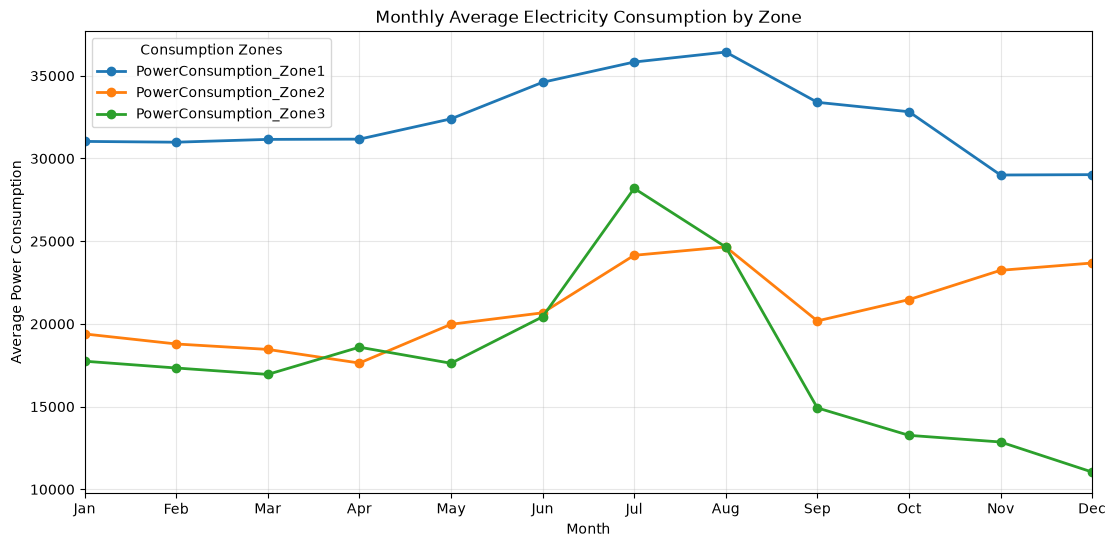

In [24]:
# Monthly consumption patterns
# Calculate monthly average consumption

# Aggregate original observations into monthly averages
monthly_consumption = (
    df_time[consumption_columns]
    .resample("MS")
    .mean()
)

# Display monthly consumption
print("MONTHLY AVERAGE ELECTRICITY CONSUMPTION")
display(monthly_consumption.round(2))

# Identify the highest and lowest consumption months
print("\nHIGHEST MONTHLY AVERAGE")

display(
    monthly_consumption.idxmax().to_frame("Highest Consumption Month")
)

print("\nLOWEST MONTHLY AVERAGE")

display(
    monthly_consumption.idxmin().to_frame("Lowest Consumption Month")
)

# Visualise monthly patterns

# Plot monthly average consumption for all zones
monthly_consumption.plot(
    figsize=(13, 6),
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Electricity Consumption by Zone")
plt.xlabel("Month")
plt.ylabel("Average Power Consumption")
plt.xticks(monthly_consumption.index, monthly_consumption.index.strftime("%b"))
plt.grid(alpha=0.3)
plt.legend(title="Consumption Zones")
plt.show()


<!-- Monthly analysis revealed variations in electricity consumption across the three geographical zones. Zone 1 and Zone 2 recorded their highest average consumption in August 2017, while Zone 3 peaked in July 2017. The lowest average consumption occurred in November for Zone 1, April for Zone 2, and December for Zone 3. These differences suggest that the three zones experienced distinct monthly consumption patterns during the observation period. However, because the dataset covers only one year, the observed monthly changes cannot establish recurring annual seasonality. -->

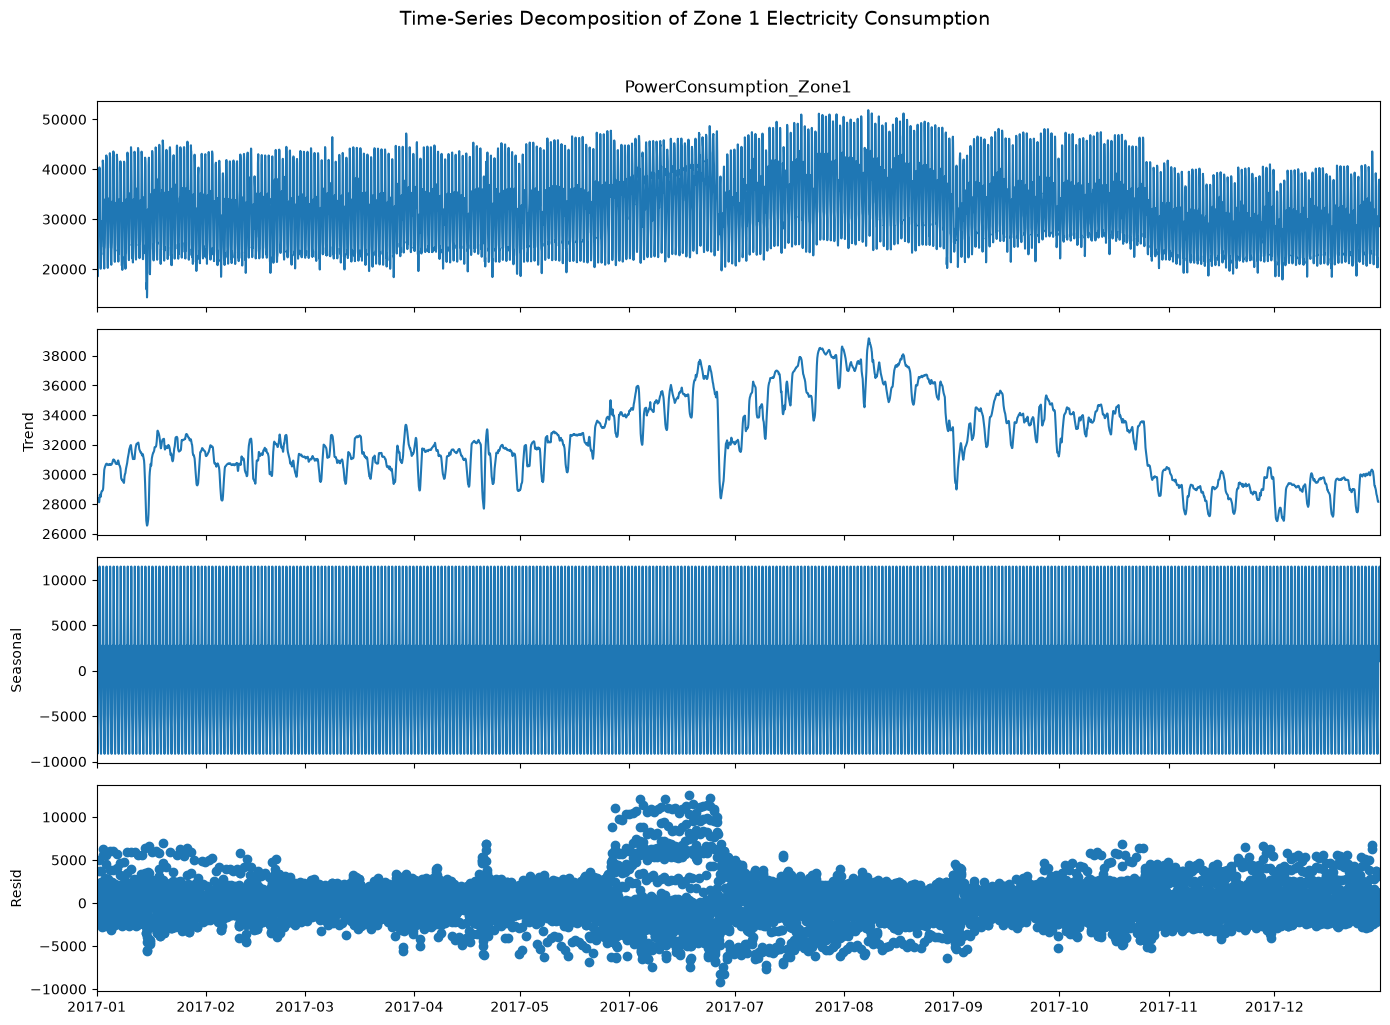

TREND COMPONENT


count     8712.00
mean     32356.45
std       2647.28
min      26545.21
25%      30425.10
50%      31934.35
75%      34131.73
max      39173.65
Name: trend, dtype: float64


SEASONAL COMPONENT


count     8736.00
mean        -0.00
std       6158.79
min      -9149.72
25%      -5829.26
50%       1305.82
75%       2722.96
max      11484.46
Name: seasonal, dtype: float64


RESIDUAL COMPONENT


count     8712.00
mean         0.64
std       2181.46
min      -9186.55
25%      -1239.98
50%        -17.31
75%       1126.42
max      12586.83
Name: resid, dtype: float64

In [26]:
# Time-Series Decomposition using Statsmodels
# Perform hourly time-series decomposition

# Import seasonal decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

# Select hourly consumption for Zone 1
zone1_hourly = hourly_consumption["PowerConsumption_Zone1"]

# Perform additive time-series decomposition
decomposition = seasonal_decompose(
    zone1_hourly,
    model="additive",
    period=24
)

# Plot the decomposition components
fig = decomposition.plot()

fig.set_size_inches(14, 10)
fig.suptitle(
    "Time-Series Decomposition of Zone 1 Electricity Consumption",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

# Examine the components numerically

# Extract the decomposition components
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Display summary statistics
print("TREND COMPONENT")
display(trend.describe().round(2))

print("\nSEASONAL COMPONENT")
display(seasonal.describe().round(2))

print("\nRESIDUAL COMPONENT")
display(residual.describe().round(2))


In [28]:
# Decomposition statistics for all zones

# Compare trend, seasonal and residual components
# across all three geographical zones

decomposition_summary = []

for zone, result in decompositions.items():

    # Extract the three components
    trend = result.trend.dropna()
    seasonal = result.seasonal.dropna()
    residual = result.resid.dropna()

    # Store summary statistics
    decomposition_summary.append({
        "Zone": zone,

        "Trend Mean": trend.mean(),
        "Trend Std": trend.std(),
        "Trend Min": trend.min(),
        "Trend Max": trend.max(),

        "Seasonal Mean": seasonal.mean(),
        "Seasonal Std": seasonal.std(),
        "Seasonal Min": seasonal.min(),
        "Seasonal Max": seasonal.max(),

        "Residual Mean": residual.mean(),
        "Residual Std": residual.std(),
        "Residual Min": residual.min(),
        "Residual Max": residual.max()
    })

# Convert results into a DataFrame
decomposition_summary = pd.DataFrame(decomposition_summary)

# Display the comparison
display(decomposition_summary.round(3))

# Compare the components separately

# Extract trend statistics
trend_comparison = decomposition_summary[
    ["Zone", "Trend Mean", "Trend Std", "Trend Min", "Trend Max"]
]

# Extract seasonal statistics
seasonal_comparison = decomposition_summary[
    ["Zone", "Seasonal Mean", "Seasonal Std",
     "Seasonal Min", "Seasonal Max"]
]

# Extract residual statistics
residual_comparison = decomposition_summary[
    ["Zone", "Residual Mean", "Residual Std",
     "Residual Min", "Residual Max"]
]

print("TREND COMPONENT COMPARISON")
display(trend_comparison.round(2))

print("\nSEASONAL COMPONENT COMPARISON")
display(seasonal_comparison.round(2))

print("\nRESIDUAL COMPONENT COMPARISON")
display(residual_comparison.round(2))

# Identify the zone with the greatest variability

# Identify the zone with the greatest variability
# in each decomposition component

print("GREATEST TREND VARIABILITY:")
print(
    decomposition_summary.loc[
        decomposition_summary["Trend Std"].idxmax(),
        ["Zone", "Trend Std"]
    ]
)

print("\nGREATEST SEASONAL VARIABILITY:")
print(
    decomposition_summary.loc[
        decomposition_summary["Seasonal Std"].idxmax(),
        ["Zone", "Seasonal Std"]
    ]
)

print("\nGREATEST RESIDUAL VARIABILITY:")
print(
    decomposition_summary.loc[
        decomposition_summary["Residual Std"].idxmax(),
        ["Zone", "Residual Std"]
    ]
)


,Zone,Trend Mean,Trend Std,Trend Min,Trend Max,Seasonal Mean,Seasonal Std,Seasonal Min,Seasonal Max,Residual Mean,Residual Std,Residual Min,Residual Max
0,PowerConsumption_Zone1,32356.448,2647.279,26545.211,39173.651,-0.0,6158.791,-9149.716,11484.462,0.640,2181.462,-9186.554,12586.826
1,PowerConsumption_Zone2,21041.990,2681.922,14335.743,28797.073,0.0,4052.053,-6108.609,7138.467,-0.537,1651.881,-6175.047,8134.797
2,PowerConsumption_Zone3,17844.694,4899.643,10456.963,32795.188,-0.0,4037.640,-6171.896,8204.276,0.715,1768.676,-7980.838,7958.611


TREND COMPONENT COMPARISON


,Zone,Trend Mean,Trend Std,Trend Min,Trend Max
0,PowerConsumption_Zone1,32356.45,2647.28,26545.21,39173.65
1,PowerConsumption_Zone2,21041.99,2681.92,14335.74,28797.07
2,PowerConsumption_Zone3,17844.69,4899.64,10456.96,32795.19



SEASONAL COMPONENT COMPARISON


,Zone,Seasonal Mean,Seasonal Std,Seasonal Min,Seasonal Max
0,PowerConsumption_Zone1,-0.0,6158.79,-9149.72,11484.46
1,PowerConsumption_Zone2,0.0,4052.05,-6108.61,7138.47
2,PowerConsumption_Zone3,-0.0,4037.64,-6171.90,8204.28



RESIDUAL COMPONENT COMPARISON


,Zone,Residual Mean,Residual Std,Residual Min,Residual Max
0,PowerConsumption_Zone1,0.64,2181.46,-9186.55,12586.83
1,PowerConsumption_Zone2,-0.54,1651.88,-6175.05,8134.80
2,PowerConsumption_Zone3,0.72,1768.68,-7980.84,7958.61


GREATEST TREND VARIABILITY:
Zone         PowerConsumption_Zone3
Trend Std               4899.642642
Name: 2, dtype: object

GREATEST SEASONAL VARIABILITY:
Zone            PowerConsumption_Zone1
Seasonal Std               6158.790999
Name: 0, dtype: object

GREATEST RESIDUAL VARIABILITY:
Zone            PowerConsumption_Zone1
Residual Std               2181.462188
Name: 0, dtype: object


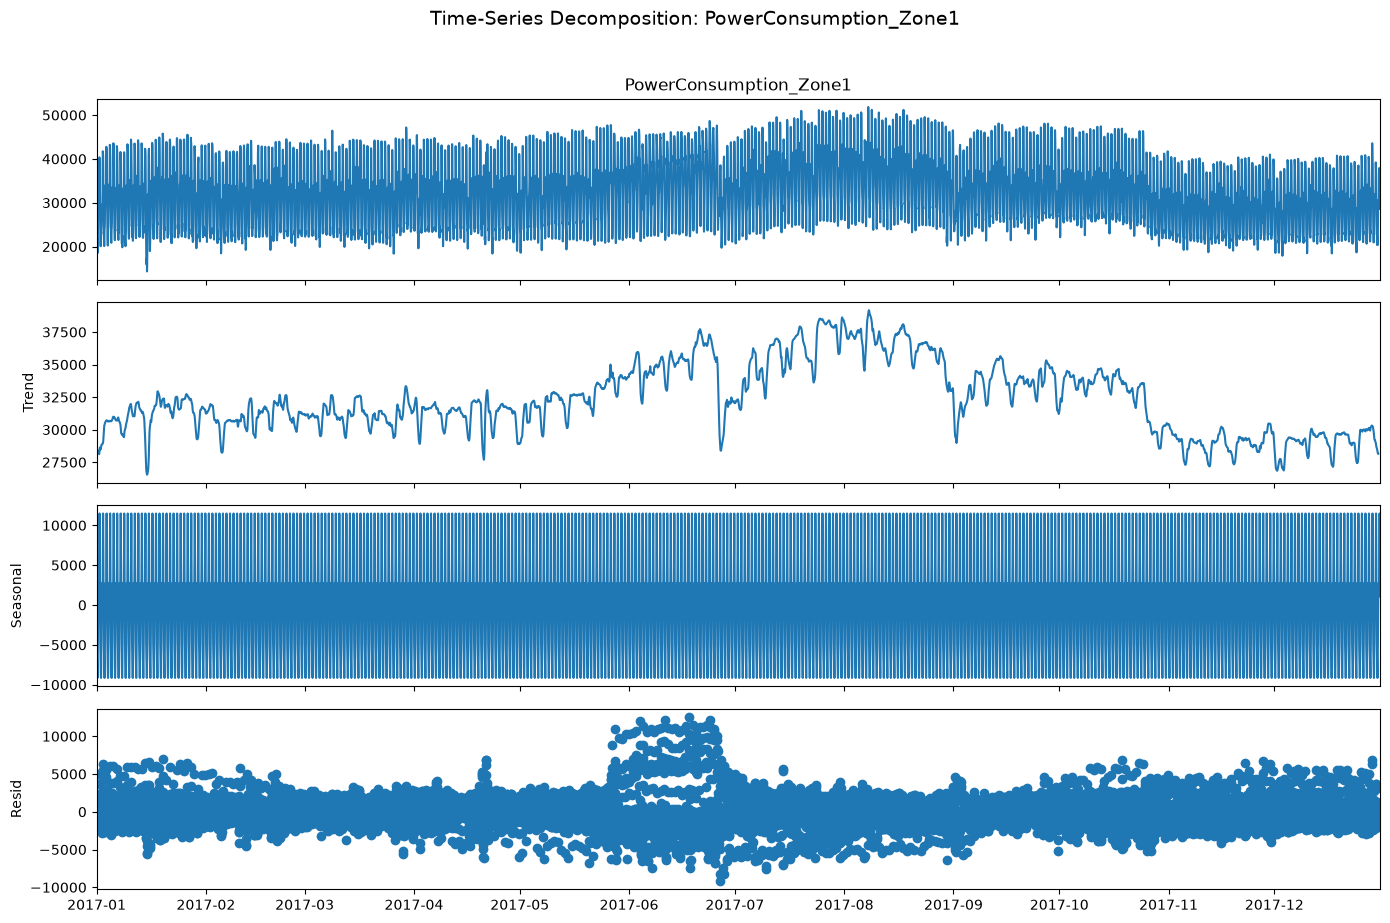

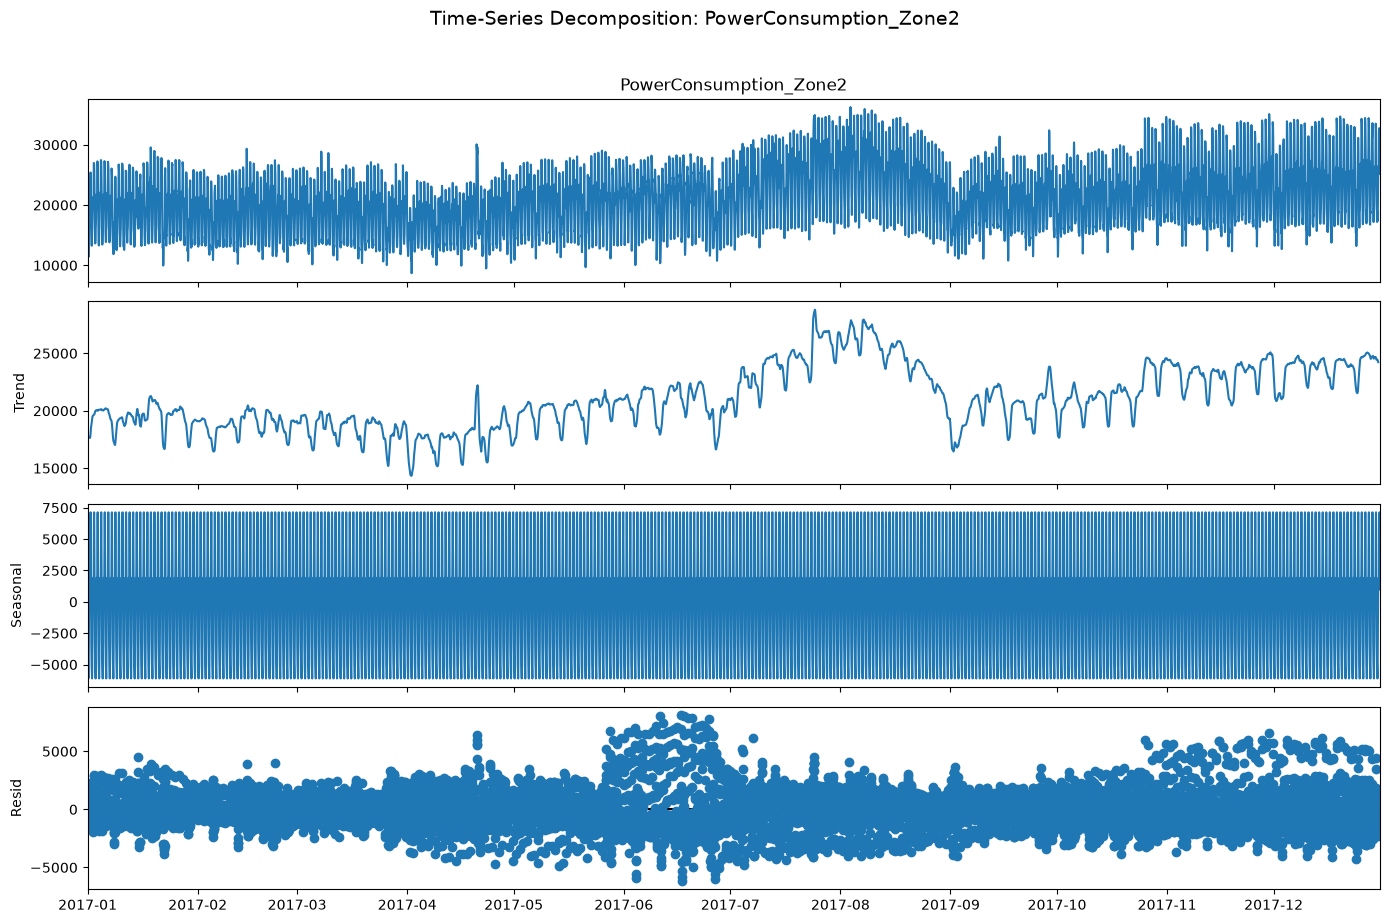

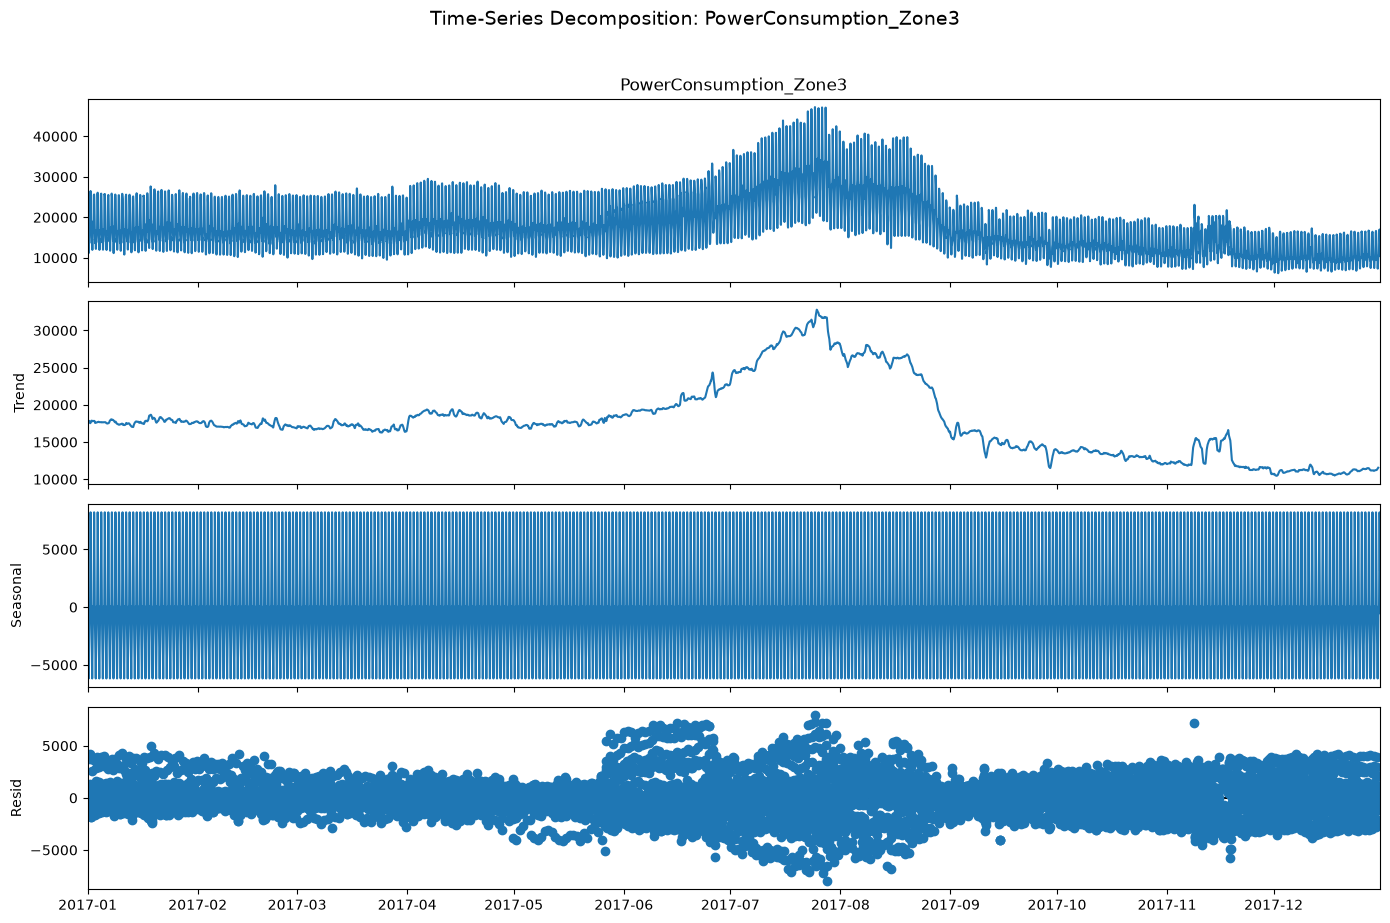

In [27]:
# Decomposition of all three zones

# Perform time-series decomposition for all three zones

decompositions = {}

for column in consumption_columns:

    # Extract the hourly consumption series
    series = hourly_consumption[column]

    # Apply additive decomposition with a 24-hour period
    result = seasonal_decompose(
        series,
        model="additive",
        period=24
    )

    # Store the result
    decompositions[column] = result

    # Display decomposition plot
    fig = result.plot()
    fig.set_size_inches(14, 9)

    fig.suptitle(
        f"Time-Series Decomposition: {column}",
        fontsize=14,
        y=1.02
    )

    plt.tight_layout()
    plt.show()


<!-- . Seasonal variability: Zone 1
Zone 1 has the highest seasonal standard deviation of 6,158.79.

This suggests that Zone 1 experiences the strongest recurring daily fluctuations. Its consumption changes more significantly throughout the day compared with the other zones.
 Residual variability: Zone 1
Zone 1 also has the highest residual standard deviation of 2,181.46.

This indicates that, after accounting for the estimated trend and daily seasonal pattern, Zone 1 retains the greatest unexplained variation. This could reflect irregular consumption changes or other factors not captured by the decomposition.

The time-series decomposition revealed different consumption behaviours across the three geographical zones. Zone 3 recorded the highest trend variability, indicating greater fluctuations in its underlying consumption pattern. Zone 1 showed the highest seasonal variability, suggesting stronger daily consumption fluctuations. It also recorded the highest residual variability, indicating more unexplained variation after removing the estimated trend and seasonal components.

Overall, the findings suggest that electricity consumption patterns differ across the three zones. These differences may be useful for planning demand forecasting, identifying unusual consumption behaviour, and improving energy management strategies. -->

<!-- Task 4: Environmental Statistical Analysis
For this task, we want to investigate whether changes in environmental conditions are associated with changes in electricity consumption across the three zones.

We'll examine:
1. Temperature and electricity consumption.
2. Humidity and electricity consumption.
3. Wind speed and electricity consumption.
We'll calculate correlation coefficients, visualize the relationships, conduct appropriate statistical tests, and interpret the results. -->

In [29]:
# Environmental variables to investigate
environmental_columns = [
    "Temperature",
    "Humidity",
    "WindSpeed"
]

# Calculate hourly averages for environmental variables
hourly_environment = (
    df_time[environmental_columns]
    .resample("h")
    .mean()
)

# Combine environmental data with hourly electricity consumption
environmental_data = pd.concat(
    [hourly_environment, hourly_consumption],
    axis=1
)

# Display the first five observations
display(environmental_data.head())

# Check the dataset dimensions
print("Dataset shape:", environmental_data.shape)

# Check for missing values
print("\nMissing values:")
print(environmental_data.isnull().sum())

,Temperature,Humidity,WindSpeed,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Hour
Datetime,,,,,,,
2017-01-01 00:00:00,6.196833,75.066667,0.081833,29197.974683,18026.747720,19252.048193,0
2017-01-01 01:00:00,5.548833,77.583333,0.082000,24657.215190,16078.419453,17042.891567,1
2017-01-01 02:00:00,5.054333,78.933333,0.082333,22083.037973,14330.699088,15676.144578,2
2017-01-01 03:00:00,5.004333,77.083333,0.082833,20811.139240,13219.452887,14883.855422,3
2017-01-01 04:00:00,5.097667,74.050000,0.082333,20475.949367,12921.580547,14317.108433,4


Dataset shape: (8736, 7)

Missing values:
Temperature               0
Humidity                  0
WindSpeed                 0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
Hour                      0
dtype: int64


In [30]:
# Calculate Pearson and Spearman correlations
# Define the environmental variables
environmental_columns = [
    "Temperature",
    "Humidity",
    "WindSpeed"
]

# Define the electricity consumption columns
consumption_columns = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]

# Store correlation results
correlation_results = []

# Calculate Pearson and Spearman correlations
for environment in environmental_columns:

    for zone in consumption_columns:

        # Pearson correlation
        pearson_corr, pearson_p = stats.pearsonr(
            environmental_data[environment],
            environmental_data[zone]
        )

        # Spearman correlation
        spearman_corr, spearman_p = stats.spearmanr(
            environmental_data[environment],
            environmental_data[zone]
        )

        # Save results
        correlation_results.append({
            "Environmental Factor": environment,
            "Consumption Zone": zone,
            "Pearson Correlation": pearson_corr,
            "Pearson P-value": pearson_p,
            "Spearman Correlation": spearman_corr,
            "Spearman P-value": spearman_p
        })

# Convert results into a DataFrame
correlation_df = pd.DataFrame(correlation_results)

# Display results
display(correlation_df.round(4))

,Environmental Factor,Consumption Zone,Pearson Correlation,Pearson P-value,Spearman Correlation,Spearman P-value
0,Temperature,PowerConsumption_Zone1,0.4439,0.0,0.4353,0.0
1,Temperature,PowerConsumption_Zone2,0.3848,0.0,0.3803,0.0
2,Temperature,PowerConsumption_Zone3,0.4921,0.0,0.4379,0.0
3,Humidity,PowerConsumption_Zone1,-0.2908,0.0,-0.3016,0.0
4,Humidity,PowerConsumption_Zone2,-0.2979,0.0,-0.3112,0.0
5,Humidity,PowerConsumption_Zone3,-0.2351,0.0,-0.2132,0.0
6,WindSpeed,PowerConsumption_Zone1,0.1696,0.0,0.1148,0.0
7,WindSpeed,PowerConsumption_Zone2,0.1480,0.0,0.0937,0.0
8,WindSpeed,PowerConsumption_Zone3,0.2810,0.0,0.0837,0.0


<!-- Notice these differences:
- Temperature in Zone 3: Pearson = 0.4921, Spearman = 0.4379.
- Wind Speed in Zone 3: Pearson = 0.2810, Spearman = 0.0837.
The difference for wind speed in Zone 3 is particularly interesting. It suggests that the linear association is stronger than the overall monotonic rank association. -->

In [32]:
import pandas as pd

correlation_df = pd.DataFrame(correlation_results)
print(correlation_df.to_string(float_format="%.10e"))


  Environmental Factor        Consumption Zone  Pearson Correlation   Pearson P-value  Spearman Correlation  Spearman P-value
0          Temperature  PowerConsumption_Zone1     4.4386312699e-01  0.0000000000e+00      4.3529371734e-01  0.0000000000e+00
1          Temperature  PowerConsumption_Zone2     3.8483270203e-01 2.2977365061e-306      3.8026501755e-01 1.3512903884e-298
2          Temperature  PowerConsumption_Zone3     4.9212361973e-01  0.0000000000e+00      4.3788270893e-01  0.0000000000e+00
3             Humidity  PowerConsumption_Zone1    -2.9076378736e-01 8.6889908727e-170     -3.0161957593e-01 3.5753749167e-183
4             Humidity  PowerConsumption_Zone2    -2.9788506173e-01 1.6751886060e-178     -3.1121197567e-01 1.7184973734e-195
5             Humidity  PowerConsumption_Zone3    -2.3509997860e-01 5.2961811501e-110     -2.1324165195e-01  2.1804192918e-90
6            WindSpeed  PowerConsumption_Zone1     1.6957330539e-01  2.3171060551e-57      1.1475488270e-01  5.3302446

<!-- 1. Correlation Method Selection
I selected both Pearson and Spearman correlation methods to investigate the relationships between environmental variables (Temperature, Humidity and Wind Speed) and electricity consumption across the three zones.

The two methods provide complementary insights:
- Pearson correlation: Measures the strength and direction of a linear relationship between two continuous variables. It is appropriate when the relationship is approximately linear and observations are suitable for the assumptions of the test.
- Spearman correlation: Measures the strength and direction of a monotonic relationship using ranked values. It is useful when relationships are nonlinear but consistently increasing or decreasing, or when outliers and non-normal distributions make Pearson less representative.
Using both methods allows us to compare linear relationships with broader monotonic patterns rather than relying on a single correlation measure. -->

In [35]:
!mamba install nbformat 

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, statsmodels, plotly, nbformat
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 5.832 seconds
All requested packages already installed.


In [44]:
# Conducting Statistical Tests
from scipy.stats import pearsonr, spearmanr

from itertools import product

results = []

for factor, zone in product(
    environmental_factors,
    consumption_zones
):

    clean_data = df[[factor, zone]].dropna()

    pearson_r, pearson_p = pearsonr(
        clean_data[factor],
        clean_data[zone]
    )

    spearman_r, spearman_p = spearmanr(
        clean_data[factor],
        clean_data[zone]
    )

    results.append({
        'Environmental Factor': factor,
        'Consumption Zone': zone,
        'Pearson r': pearson_r,
        'Pearson p-value': pearson_p,
        'Spearman r': spearman_r,
        'Spearman p-value': spearman_p
    })

correlation_results = pd.DataFrame(results)

correlation_results

,Environmental Factor,Consumption Zone,Pearson r,Pearson p-value,Spearman r,Spearman p-value
0,Temperature,PowerConsumption_Zone1,0.440221,0.000000e+00,0.432621,0.000000e+00
1,Temperature,PowerConsumption_Zone2,0.382428,0.000000e+00,0.378803,0.000000e+00
2,Temperature,PowerConsumption_Zone3,0.489527,0.000000e+00,0.436290,0.000000e+00
3,Humidity,PowerConsumption_Zone1,-0.287421,0.000000e+00,-0.299703,0.000000e+00
4,Humidity,PowerConsumption_Zone2,-0.294961,0.000000e+00,-0.308970,0.000000e+00
5,Humidity,PowerConsumption_Zone3,-0.233022,0.000000e+00,-0.211801,0.000000e+00
6,WindSpeed,PowerConsumption_Zone1,0.167444,0.000000e+00,0.106679,1.757203e-132
7,WindSpeed,PowerConsumption_Zone2,0.146413,5.471069e-249,0.087419,1.936905e-89
8,WindSpeed,PowerConsumption_Zone3,0.278641,0.000000e+00,0.078981,2.652108e-73


<!-- Interpreting the Strength and Direction of Relationships

Temperature

Temperature has a moderate positive relationship with electricity consumption across all three zones. Zone 3 has the strongest association (0.4921), suggesting that electricity consumption in this zone is more strongly associated with temperature changes.

Humidity

Humidity has a weak negative relationship with electricity consumption across all three zones. Zone 2 records the strongest negative association (-0.2979).

Wind Speed

Wind speed has a weak positive relationship with electricity consumption. Zone 3 records the strongest association (0.2810), while Zone 2 has the weakest (0.1480).

Overall, temperature demonstrates the strongest pairwise association with electricity consumption, followed by humidity and wind speed. -->

<!-- Limitations and Potential Confounding Factors
Although the correlation analysis provides useful insights, several limitations should be considered.

1. Temporal dependence

Electricity consumption is time-dependent. Consumption at one hour may be influenced by consumption in previous hours. This can violate the independence assumption of conventional correlation significance tests.

2. Potential confounding factors

Environmental variables may not independently explain electricity consumption. Other factors could influence the observed relationships, including:
- Hour of the day.
- Day of the week.
- Seasonal changes.
- Public holidays.
- Industrial and commercial activities.
- Population and household electricity demand.
- Electricity pricing and usage patterns.
3. Correlation does not imply causation

A positive relationship between temperature and electricity consumption does not prove that increasing temperature directly causes higher electricity consumption. Other variables may contribute to the observed pattern.

4. Linear relationship limitations

Pearson correlation measures linear association. Some environmental factors may have nonlinear relationships with electricity consumption, which could be overlooked.

5. Statistical significance versus practical significance

A large dataset can produce very small p-values even when the correlation is weak. Therefore, the magnitude of the correlation should be considered alongside its statistical significance. -->

In [45]:
# Comparative Zone Analysis
# The goal is to determine which zone consumes more electricity, which experiences greater fluctuations, 
# and whether their consumption patterns differ over time.

import pandas as pd
import numpy as np
import plotly.express as px
from scipy.stats import f_oneway, kruskal, levene
from pathlib import Path

# 1. Define consumption zones
zones = [
    'PowerConsumption_Zone1',
    'PowerConsumption_Zone2',
    'PowerConsumption_Zone3'
]

# 2. Prepare data
data = df.copy()
data['Datetime'] = pd.to_datetime(data['Datetime'])

# 3. Descriptive statistics
zone_summary = data[zones].agg([
    'count', 'mean', 'median', 'std', 'var',
    'min', 'max', 'skew'
]).T

zone_summary['Range'] = zone_summary['max'] - zone_summary['min']
zone_summary['IQR'] = (
    data[zones].quantile(0.75) -
    data[zones].quantile(0.25)
)

zone_summary['CV (%)'] = (
    zone_summary['std'] / zone_summary['mean'] * 100
)

print("DESCRIPTIVE STATISTICS")
display(zone_summary.round(3))

# 4. Identify highest average and variability
print("\nHIGHEST AVERAGE CONSUMPTION:")
print(zone_summary['mean'].idxmax())

print("\nGREATEST VARIABILITY (STANDARD DEVIATION):")
print(zone_summary['std'].idxmax())

print("\nGREATEST RELATIVE VARIABILITY (CV):")
print(zone_summary['CV (%)'].idxmax())

# 5. Prepare data for visualization
long_data = data.melt(
    id_vars=['Datetime'],
    value_vars=zones,
    var_name='Zone',
    value_name='Consumption'
)

# 6. Compare overall consumption distributions
fig = px.box(
    long_data,
    x='Zone',
    y='Consumption',
    color='Zone',
    title='Electricity Consumption Distribution Across Zones'
)
fig.update_layout(template='plotly_white', showlegend=False)
fig.write_html('zone_distribution.html', include_plotlyjs=True)

# 7. Compare average hourly consumption
data['Hour'] = data['Datetime'].dt.hour

hourly_data = (
    data.groupby('Hour')[zones]
    .mean()
    .reset_index()
)

hourly_long = hourly_data.melt(
    id_vars='Hour',
    value_vars=zones,
    var_name='Zone',
    value_name='Average Consumption'
)

fig = px.line(
    hourly_long,
    x='Hour',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Average Hourly Electricity Consumption Across Zones'
)
fig.update_layout(template='plotly_white')
fig.write_html('hourly_comparison.html', include_plotlyjs=True)

# 8. Compare average monthly consumption
data['Month'] = data['Datetime'].dt.month

monthly_data = (
    data.groupby('Month')[zones]
    .mean()
    .reset_index()
)

monthly_long = monthly_data.melt(
    id_vars='Month',
    value_vars=zones,
    var_name='Zone',
    value_name='Average Consumption'
)

fig = px.line(
    monthly_long,
    x='Month',
    y='Average Consumption',
    color='Zone',
    markers=True,
    title='Average Monthly Electricity Consumption Across Zones'
)
fig.update_layout(
    template='plotly_white',
    xaxis=dict(
        tickmode='array',
        tickvals=list(range(1, 13)),
        ticktext=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                  'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    )
)
fig.write_html('monthly_comparison.html', include_plotlyjs=True)

# 9. Statistical tests: Compare average consumption
zone_values = [data[z].dropna().values for z in zones]

# One-way ANOVA
anova_stat, anova_p = f_oneway(*zone_values)

# Kruskal-Wallis test
kruskal_stat, kruskal_p = kruskal(*zone_values)

print("\nSTATISTICAL TESTS")
print(f"ANOVA Statistic: {anova_stat:.4f}")
print(f"ANOVA P-value: {anova_p:.4e}")
print(f"Kruskal-Wallis Statistic: {kruskal_stat:.4f}")
print(f"Kruskal-Wallis P-value: {kruskal_p:.4e}")

# 10. Compare variances
levene_stat, levene_p = levene(*zone_values)

print(f"\nLevene Statistic: {levene_stat:.4f}")
print(f"Levene P-value: {levene_p:.4e}")

# 11. Interpret statistical results
print("\nINTERPRETATION")

if anova_p < 0.05:
    print("ANOVA: Significant differences exist among zone means.")
else:
    print("ANOVA: No statistically significant difference detected.")

if kruskal_p < 0.05:
    print("Kruskal-Wallis: At least one zone has a different distribution.")
else:
    print("Kruskal-Wallis: No statistically significant distribution difference detected.")

if levene_p < 0.05:
    print("Levene: Zone variances differ significantly.")
else:
    print("Levene: No statistically significant variance difference detected.")

print("\nAnalysis completed successfully.")


DESCRIPTIVE STATISTICS


,count,mean,median,std,var,min,max,skew,Range,IQR,CV (%)
PowerConsumption_Zone1,52416.0,32344.971,32265.920,7130.563,5.084492e+07,13895.696,52204.395,0.229,38308.699,10998.349,22.045
PowerConsumption_Zone2,52416.0,21042.509,20823.168,5201.466,2.705525e+07,8560.081,37408.861,0.329,28848.779,7732.951,24.719
PowerConsumption_Zone3,52416.0,17835.406,16415.117,6622.165,4.385307e+07,5935.174,47598.326,1.024,41663.152,8494.774,37.129



HIGHEST AVERAGE CONSUMPTION:
PowerConsumption_Zone1

GREATEST VARIABILITY (STANDARD DEVIATION):
PowerConsumption_Zone1

GREATEST RELATIVE VARIABILITY (CV):
PowerConsumption_Zone3

STATISTICAL TESTS
ANOVA Statistic: 75028.9996
ANOVA P-value: 0.0000e+00
Kruskal-Wallis Statistic: 76069.5909
Kruskal-Wallis P-value: 0.0000e+00

Levene Statistic: 2436.2121
Levene P-value: 0.0000e+00

INTERPRETATION
ANOVA: Significant differences exist among zone means.
Kruskal-Wallis: At least one zone has a different distribution.
Levene: Zone variances differ significantly.

Analysis completed successfully.


<!-- So far, our major findings are:
- Highest average consumption: Zone 1.
- Greatest absolute variability: Zone 1.
- Greatest relative variability: Zone 3.
- Significant differences in consumption distributions and variances: Indicated by your preliminary statistical tests. -->